# Checkpoint — KMeans & DBSCAN

Dit notebook wordt automatisch gecheckt via pytest (GitHub Actions). De checks voeren je notebook uit en valideren of bepaalde variabelen bestaan en binnen de verwachte ranges vallen. **Je krijgt geen hints in de foutmeldingen: het is aan jou om correct werkende code te schrijven.**

## BELANGRIJK: gebruik exact de genoemde variabelennamen

De checks zoeken volgende variabelen in je notebook. Andere namen worden niet gezien:

- `best_k_wine` — de gekozen waarde van k voor de Wine-dataset (int)
- `silhouette_wine` — de silhouette score van die keuze (float)
- `image` — de ingeladen afbeelding (3D numpy-array)
- `n_colors` — het tuple van aantal kleuren `(10, 8, 6, 4, 2)`
- `segmented_imgs` — de lijst van gesegmenteerde afbeeldingen (5 elementen, zelfde vorm als `image`)
- `best_k_iris` — de gekozen waarde van k voor de Iris-dataset (int)
- `silhouette_iris` — de silhouette score van die keuze (float)
- `best_k_mall` — de gekozen waarde van k voor de Mall-dataset (int)
- `silhouette_mall` — de silhouette score van die keuze (float)
- `antwoord_iris` — meerkeuzevraag 1: `"A"`, `"B"`, `"C"` of `"D"`
- `antwoord_dbscan` — meerkeuzevraag 2: `"A"`, `"B"`, `"C"` of `"D"`

Gebruik overal `random_state=42` (en `n_init=10`) bij KMeans zodat je resultaten reproduceerbaar zijn en binnen de verwachte drempels vallen. Werk met de lokale afbeelding `images/butterfly.jpg` (er wordt niets gedownload).

## Oefening 1 — Wijn

Cluster de Wine-dataset zo optimaal mogelijk met KMeans. De dataset heeft 13 features op verschillende schalen, dus **schaal eerst met `StandardScaler`**.

Probeer verschillende waarden van `k`, bereken telkens de **silhouette score** en kies de `k` met de hoogste score.

Bewaar je keuze in `best_k_wine` en de bijhorende score in `silhouette_wine`.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

wine = datasets.load_wine()
data = wine.data

# Schaal de data zodat alle features gelijk gewicht krijgen
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)

Bij 3 clusters is de silhouette score optimaal binnen het bereik K(2,8) met 0.2848589191898987


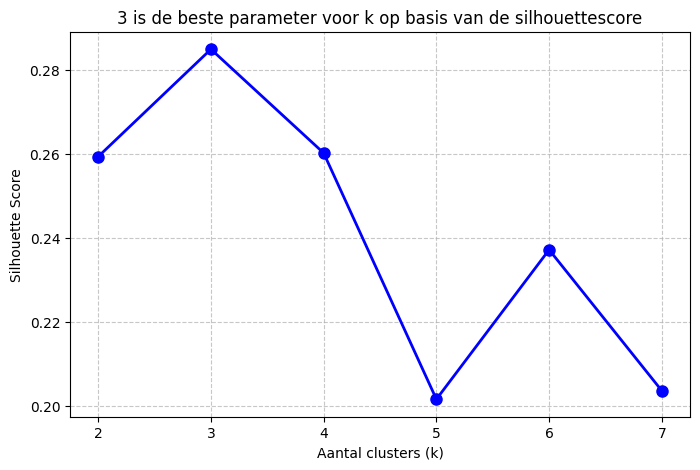

In [5]:
# TODO: bereken voor elke k in range(2, 8) de silhouette score (KMeans met
# random_state=42, n_init=10). Bewaar de k met de hoogste score in best_k_wine
# en die score in silhouette_wine.
best_k_wine = 2
silhouette_wine = 0.0
scores = []

for k in range(2,8):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans = kmeans.fit(data_scaled)
    score = silhouette_score(data_scaled, kmeans.labels_)
    scores.append(score)
    if score > silhouette_wine:
        silhouette_wine = score
        best_k_wine = k

print(f"Bij {best_k_wine} clusters is de silhouette score optimaal binnen het bereik K(2,8) met {silhouette_wine}")

# De x-as waarden (de k's die je hebt getest)
k_values = range(2, 8)

plt.figure(figsize=(8, 5))
# 'o:' zorgt voor bolletjes op de datapunten verbonden met een stippellijn
plt.plot(k_values, scores, marker='o', linestyle='-', color='b', linewidth=2, markersize=8)

plt.title('3 is de beste parameter voor k op basis van de silhouettescore')
plt.xlabel('Aantal clusters (k)')
plt.ylabel('Silhouette Score')
plt.xticks(k_values)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

## Oefening 2 — Image Segmentation

We gebruiken clustering om een afbeelding in stukken met gelijkaardige kleuren te verdelen. Gebruik de lokale afbeelding `images/butterfly.jpg` (533×800 pixels, 3 kleurkanalen).

Hervorm de 3D-array tot een `(n_pixels, 3)` matrix met `reshape(-1, 3)`, train dan KMeans met `n_clusters` in `(10, 8, 6, 4, 2)` en vervang elke pixel door de centroidkleur van zijn cluster. Hervorm het resultaat terug naar de originele vorm.

Bewaar het tuple `n_colors = (10, 8, 6, 4, 2)` en de 5 gesegmenteerde afbeeldingen in `segmented_imgs`.

In [10]:
import numpy as np
from PIL import Image
from sklearn.cluster import KMeans

# Gebruik het lokale voorbeeldbeeld (geen download nodig)
image = np.asarray(Image.open('images/butterfly.jpg'))
print('image shape:', image.shape)

# Hervorm de 3D-array (pixels, breedte, kanalen) naar een (n_pixels, 3) matrix
X = image.reshape(-1, 3)

image shape: (533, 800, 3)


In [11]:
# TODO: train voor elk aantal kleuren een KMeans (random_state=42, n_init=10)
# op X, vervang elke pixel door de centroidkleur van zijn cluster en hervorm
# terug naar image.shape. Bewaar alles in segmented_imgs (volgorde van n_colors).
n_colors = (10, 8, 6, 4, 2)
segmented_imgs = []
for n_clusters in n_colors:
    kmeans = KMeans(n_clusters=n_clusters, n_init=10, random_state=42).fit(X)
    segmented_img = kmeans.cluster_centers_[kmeans.labels_]
    segmented_imgs.append(segmented_img.reshape(image.shape))
    


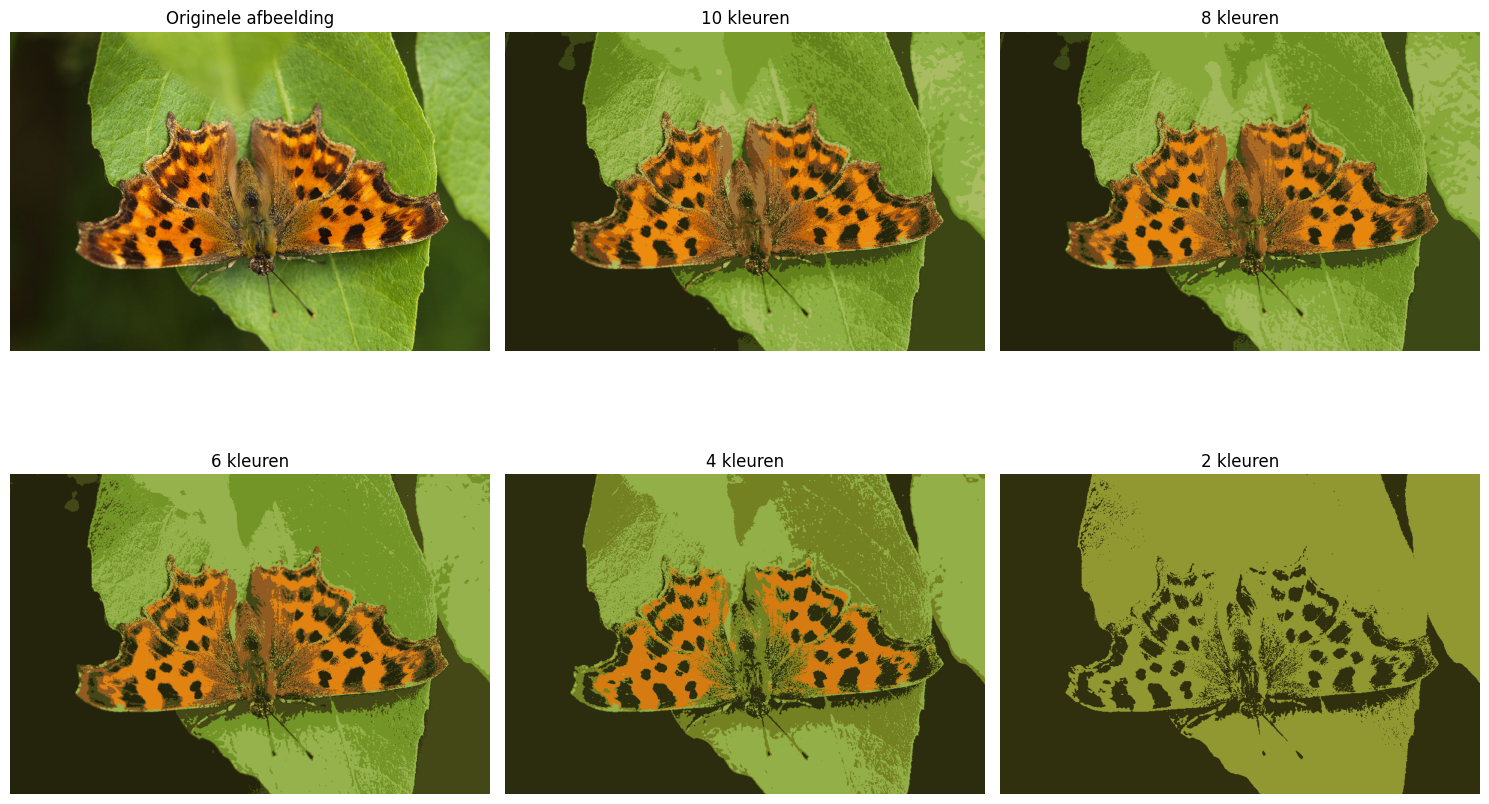

In [12]:
# Maak een grid van 2 rijen en 3 kolommen
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Maak de grid plat (1D) zodat we er makkelijk overheen kunnen loopen
axes = axes.flatten()

# Toon de originele afbeelding in het eerste vakje
axes[0].imshow(image)
axes[0].set_title('Originele afbeelding')
axes[0].axis('off')

# Loop door onze n_colors en de bijbehorende gesegmenteerde afbeeldingen
for i, (n_clusters, img) in enumerate(zip(n_colors, segmented_imgs)):
    ax = axes[i + 1] # +1 omdat index 0 al bezet is door het origineel
    
    # Converteer de floats terug naar uint8 (0-255) voor correcte weergave
    ax.imshow(img.astype(np.uint8))
    ax.set_title(f'{n_clusters} kleuren')
    ax.axis('off')

plt.tight_layout()
plt.show()

## Oefening 3 — KMeans vs DBSCAN op Iris

De Iris-dataset bevat 3 soorten die in de feature-ruimte goed gescheiden, **bolvormige** clusters van **gelijkaardige dichtheid** vormen.

Pas zowel KMeans (verschillende `k`) als DBSCAN (verschillende `eps`/`min_samples`) toe op de **gestandaardiseerde** data en vergelijk met de silhouette score. Bewaar je gekozen `k` in `best_k_iris` en de hoogste silhouette in `silhouette_iris`. Beantwoord daarna vraag 1 in `antwoord_iris`.

In [19]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

iris = load_iris()
data_scaled = StandardScaler().fit_transform(iris.data)

# TODO: pas KMeans toe voor k in range(2, 6) en DBSCAN voor een aantal
# (eps, min_samples) combinaties, en vergelijk de silhouette scores.
# Bewaar de gekozen k in best_k_iris en de hoogste silhouette in silhouette_iris.
best_k_iris = 2
silhouette_iris = 0.0

for k in range(2,6):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans = kmeans.fit(data_scaled)
    score = silhouette_score(data_scaled, kmeans.labels_)
    print(f"K = {k} | score = {score}")
    if score > silhouette_iris:
        silhouette_iris = score
        best_k_iris = k

print(f"Bij {best_k_iris} clusters is de silhouette score optimaal binnen het bereik K(2,6) met {silhouette_iris:.4f} voor KMeans\n")

for eps in np.arange(0.1,1,0.1).tolist():
    for s in range(2,11):
        dbscan = DBSCAN(eps=eps, min_samples=s).fit(data_scaled)
        unique_labels = set(dbscan.labels_)

        if len(unique_labels) > 1:
            score = silhouette_score(data_scaled, dbscan.labels_)
            print(f"Eps = {eps:.1f} | min_samples = {s} | score = {score:.4f}")
            
            if score > silhouette_iris:
                silhouette_iris = score
                print("DBSCAN had betere score dan KMeans -> Silhouette score vervangen")
        else:
            print(f"Eps = {eps:.1f} | min_samples = {s} | score = N/A (te weinig clusters)")

print(f"\nFinale silhouettescore: {silhouette_iris}")


K = 2 | score = 0.5817500491982808
K = 3 | score = 0.45994823920518635
K = 4 | score = 0.38694104154427816
K = 5 | score = 0.3459012795948778
Bij 2 clusters is de silhouette score optimaal binnen het bereik K(2,6) met 0.5818 voor KMeans

Eps = 0.1 | min_samples = 2 | score = -0.1791
Eps = 0.1 | min_samples = 3 | score = N/A (te weinig clusters)
Eps = 0.1 | min_samples = 4 | score = N/A (te weinig clusters)
Eps = 0.1 | min_samples = 5 | score = N/A (te weinig clusters)
Eps = 0.1 | min_samples = 6 | score = N/A (te weinig clusters)
Eps = 0.1 | min_samples = 7 | score = N/A (te weinig clusters)
Eps = 0.1 | min_samples = 8 | score = N/A (te weinig clusters)
Eps = 0.1 | min_samples = 9 | score = N/A (te weinig clusters)
Eps = 0.1 | min_samples = 10 | score = N/A (te weinig clusters)
Eps = 0.2 | min_samples = 2 | score = -0.3711
Eps = 0.2 | min_samples = 3 | score = 0.0871
Eps = 0.2 | min_samples = 4 | score = 0.0251
Eps = 0.2 | min_samples = 5 | score = N/A (te weinig clusters)
Eps = 0.2 | 

## Oefening 4 — KMeans vs DBSCAN op Mall

De Mall-dataset (`data/Mall_Customers.csv`) bevat klanten met `Age`, `Annual Income (k$)` en `Spending Score (1-100)`. De clusters hebben **sterk verschillende dichtheden**, waardoor DBSCAN het vaak moeilijk heeft.

Pas KMeans (verschillende `k`) en DBSCAN (verschillende `eps`/`min_samples`) toe op de **gestandaardiseerde** data en vergelijk met de silhouette score. Bewaar je gekozen `k` in `best_k_mall` en de hoogste silhouette in `silhouette_mall`. Beantwoord daarna vraag 2 in `antwoord_dbscan`.

In [20]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

mall = pd.read_csv('data/Mall_Customers.csv')
features = mall[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']]
data_scaled = StandardScaler().fit_transform(features)

# TODO: vergelijk KMeans (verschillende k's) met DBSCAN (verschillende
# eps/min_samples) via de silhouette score. Bewaar de gekozen k in best_k_mall
# en de hoogste silhouette in silhouette_mall.
best_k_mall = 5
silhouette_mall = 0.0

for k in range(2,20):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans = kmeans.fit(data_scaled)
    score = silhouette_score(data_scaled, kmeans.labels_)
    print(f"K = {k} | score = {score}")
    if score > silhouette_mall:
        silhouette_mall = score
        best_k_mall = k

print(f"Bij {best_k_mall} clusters is de silhouette score optimaal binnen het bereik K(2,20) met {silhouette_mall:.4f} voor KMeans\n")

for eps in np.arange(0.1,1.1,0.1).tolist():
    for s in range(2,11):
        dbscan = DBSCAN(eps=eps, min_samples=s).fit(data_scaled)
        unique_labels = set(dbscan.labels_)

        if len(unique_labels) > 1:
            score = silhouette_score(data_scaled, dbscan.labels_)
            print(f"Eps = {eps:.1f} | min_samples = {s} | score = {score:.4f}")
            
            if score > silhouette_mall:
                silhouette_mall = score
                print("DBSCAN had betere score dan KMeans -> Silhouette score vervangen")
        else:
            print(f"Eps = {eps:.1f} | min_samples = {s} | score = N/A (te weinig clusters)")

print(f"\nFinale silhouettescore: {silhouette_mall}")

K = 2 | score = 0.33547192894004574
K = 3 | score = 0.357793388710272
K = 4 | score = 0.4039582785148566
K = 5 | score = 0.41664341513732767
K = 6 | score = 0.4284167762892593
K = 7 | score = 0.417231894954916
K = 8 | score = 0.4082067042807375
K = 9 | score = 0.41769250624076476
K = 10 | score = 0.40655411010117015
K = 11 | score = 0.40861878459370105
K = 12 | score = 0.39284582303293175
K = 13 | score = 0.3856266309743293
K = 14 | score = 0.3866476836840209
K = 15 | score = 0.36567167217688384
K = 16 | score = 0.3430322002653297
K = 17 | score = 0.36252438697713385
K = 18 | score = 0.34075130284911564
K = 19 | score = 0.3407470596874124
Bij 6 clusters is de silhouette score optimaal binnen het bereik K(2,20) met 0.4284 voor KMeans

Eps = 0.1 | min_samples = 2 | score = -0.3772
Eps = 0.1 | min_samples = 3 | score = N/A (te weinig clusters)
Eps = 0.1 | min_samples = 4 | score = N/A (te weinig clusters)
Eps = 0.1 | min_samples = 5 | score = N/A (te weinig clusters)
Eps = 0.1 | min_sampl

## Meerkeuzevragen

### Vraag 1 — Iris
Op de Iris-dataset haalt KMeans een veel hogere silhouette score dan DBSCAN. Wat is de belangrijkste reden?

- **A)** De clusters zijn bolvormig en hebben een gelijkaardige dichtheid, waarvoor KMeans goed geschikt is; DBSCAN kampt met de dichtheidsverschillen.
- **B)** KMeans werkt zonder features te standaardiseren.
- **C)** DBSCAN kan nooit meer dan 2 clusters vinden.
- **D)** KMeans kent het aantal clusters op voorhand, en dat is altijd beter.

Bewaar je antwoord (`"A"`, `"B"`, `"C"` of `"D"`) in `antwoord_iris`.

### Vraag 2 — DBSCAN
Wanneer is DBSCAN een betere keuze dan KMeans?

- **A)** Wanneer de clusters een onregelmatige, niet-bolvormige vorm hebben of er outliers/ruis zijn.
- **B)** Wanneer alle clusters bolvormig en even groot zijn.
- **C)** Wanneer je altijd precies `k` clusters nodig hebt.
- **D)** Wanneer de dataset klein is en je snel wilt clusteren.

Bewaar je antwoord (`"A"`, `"B"`, `"C"` of `"D"`) in `antwoord_dbscan`.

In [6]:
# Vraag 1: antwoord_iris = "A", "B", "C" of "D"
antwoord_iris = "A"

# Vraag 2: antwoord_dbscan = "A", "B", "C" of "D"
antwoord_dbscan = "A"
